# 01 - Cleaning the raw data

**Goal:** turn every raw download into one tidy table with the same columns (`date`, `region`), correct units
and no duplicates. Missing values stay empty - we never invent numbers.

Every section follows the same pattern: **look at the raw file -> clean it -> check the result.**
The cleaning functions live in `Src/processing/clean_data.py`; this notebook calls them step by step so you can
see and explain what each one does. The pipeline script runs the same functions without the notebook.

| Output table | Used for |
|---|---|
| `static_context` | soil, terrain, cropland - one row per region |
| `rainfall_daily` | CHIRPS rain - **labels and features** |
| `weather_daily` | NASA POWER + VPD + ET0 - **features** |
| `soil_moisture_daily` | ERA5-Land (features), SMAP (validation) |
| `era5_weather_daily`, `imerg_daily`, `vegetation` | **validation only** |

In [17]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find ML/Src/processing from wherever the notebook is opened (ML/Notebooks or the project root)
here = Path.cwd().resolve()
candidates = [here, here.parent, here / "ML", here.parent / "ML", *here.parents]
PROC_SRC = next((c / "Src" / "processing" for c in candidates
                 if (c / "Src" / "processing" / "pipeline_common.py").exists()), None)
assert PROC_SRC is not None, "Could not find Src/processing - open this notebook from the ML/Notebooks folder."
sys.path.insert(0, str(PROC_SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pipeline_common import (RAW_DIR, PROC_DIR, DATA_DIR, REGIONS, REGION_NAMES,
                             read_region_files, read_static_file, load_table, save_table, longest_run)
import label_config as cfg

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"Arsi": "#1f77b4", "Bale": "#d62728", "Jimma": "#2ca02c"}
FIG_DIR = DATA_DIR.parent / "Figures"
FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print("Raw data :", RAW_DIR)
print("Processed:", PROC_DIR)
print("Figures  :", FIG_DIR)

Raw data : C:\hackaton\ML\Data\Raw
Processed: C:\hackaton\ML\Data\Processed
Figures  : C:\hackaton\ML\Figures


In [18]:
import clean_data as cd

## 1. What did we download?
A quick inventory of every raw file: rows, columns and date range. Anything missing or with a strange date range shows up here.

In [19]:
rows = []
for folder in sorted(p.name for p in RAW_DIR.iterdir() if p.is_dir()):
    for f in sorted((RAW_DIR / folder).glob("*.csv")):
        df = pd.read_csv(f)
        row = {"dataset": folder, "file": f.name, "rows": len(df), "columns": df.shape[1]}
        if "date" in df.columns:
            d = pd.to_datetime(df["date"])
            row["first_date"], row["last_date"] = d.min().date(), d.max().date()
        rows.append(row)
inventory = pd.DataFrame(rows)
inventory

,dataset,file,rows,columns,first_date,last_date
0,CHIRPS,chirps_arsi.csv,16709,3,1981-01-01,2026-09-30
1,CHIRPS,chirps_bale.csv,16709,3,1981-01-01,2026-09-30
2,CHIRPS,chirps_daily_1981_2025.csv,50127,3,1981-01-01,2026-09-30
3,CHIRPS,chirps_jimma.csv,16709,3,1981-01-01,2026-09-30
4,ERA5_LAND,era5_land_arsi.csv,16746,12,1981-01-01,2026-11-06
5,ERA5_LAND,era5_land_bale.csv,16746,12,1981-01-01,2026-11-06
6,ERA5_LAND,era5_land_jimma.csv,16746,12,1981-01-01,2026-11-06
7,GPM_IMERG,gpm_imerg_arsi.csv,10544,3,1998-01-01,2026-11-13
8,GPM_IMERG,gpm_imerg_bale.csv,10544,3,1998-01-01,2026-11-13
9,GPM_IMERG,gpm_imerg_jimma.csv,10544,3,1998-01-01,2026-11-13


## 2. Static context (soil, terrain, cropland)
These do not change from day to day, so each region gets **one row**.

* **SRTM** gives elevation and slope.
* **SoilGrids** gives clay, sand, silt, organic carbon and bulk density at three depths. Earth Engine stores them in
  "mapped units", so we convert: clay/sand/silt g/kg -> %, soil carbon dg/kg -> g/kg, bulk density cg/cm3 -> g/cm3.
* **WorldCover** gives the fraction of the 25 km area that is cropland.

In [20]:
for folder, prefix in [("SRTM", "srtm"), ("SOILGRIDS", "soilgrids"), ("WORLDCOVER", "worldcover")]:
    print(folder)
    display(read_static_file(folder, prefix).set_index("region").T.head(8))

SRTM


region,Arsi,Bale,Jimma
aspect_max,359.000000,359.000000,359.000000
aspect_mean,180.072044,150.955366,170.586623
aspect_min,0.000000,0.000000,0.000000
aspect_stdDev,106.990437,95.325122,105.794364
elevation_max,4183.000000,2860.000000,2945.000000
elevation_mean,2923.050940,1904.431086,1955.501932
elevation_min,2405.000000,1353.000000,1501.000000
elevation_stdDev,341.611234,253.396103,226.412773


SOILGRIDS


region,Arsi,Bale,Jimma
bdod_0-5cm_mean,111.003335,113.138185,108.897006
bdod_15-30cm_mean,115.007706,118.906317,113.864266
bdod_5-15cm_mean,112.778641,114.877600,110.515929
clay_0-5cm_mean,341.696291,412.692987,350.598109
clay_15-30cm_mean,359.385977,439.921138,405.959983
clay_5-15cm_mean,339.864215,423.508010,351.724264
sand_0-5cm_mean,301.988016,277.729065,307.446677
sand_15-30cm_mean,295.412479,265.910679,281.546029


WORLDCOVER


region,Arsi,Bale,Jimma
cropland_fraction,0.660192,0.440281,0.243847


In [21]:
static = cd.clean_static()


[static] SRTM + SoilGrids + WorldCover
[saved] static_context.csv               rows=      3  cols=29
region                Arsi     Bale    Jimma
aspect_max          359.00   359.00   359.00
aspect_mean         180.07   150.96   170.59
aspect_min            0.00     0.00     0.00
aspect_stddev       106.99    95.33   105.79
elevation_max      4183.00  2860.00  2945.00
elevation_mean     2923.05  1904.43  1955.50
elevation_min      2405.00  1353.00  1501.00
elevation_stddev    341.61   253.40   226.41
slope_max            40.00    64.00    50.00
slope_mean            6.68     8.65     8.57
slope_min             0.00     0.00     0.00
slope_stddev          5.48     8.45     5.44
bdod_0_5cm_mean       1.11     1.13     1.09
bdod_15_30cm_mean     1.15     1.19     1.14
bdod_5_15cm_mean      1.13     1.15     1.11
clay_0_5cm_mean      34.17    41.27    35.06
clay_15_30cm_mean    35.94    43.99    40.60
clay_5_15cm_mean     33.99    42.35    35.17
sand_0_5cm_mean      30.20    27.77    30.

**Check yourself:** elevation should be roughly 1,700-3,000 m, clay between 0 and 100 %, cropland fraction between 0 and 1.
Only 3 regions means these values take only 3 different numbers - they behave like a region label, not like a general soil effect.

## 3. Rainfall (CHIRPS)
CHIRPS is the backbone of the project: it defines the onset trigger, the dry spell and the label.

In [22]:
raw_chirps = cd.load_chirps()
display(raw_chirps.head())
print("rows:", len(raw_chirps))
print("negative values:", int((raw_chirps["precipitation"] < 0).sum()))
print("duplicate region-days:", int(raw_chirps.duplicated(["region", "date"]).sum()))
print("empty values:", int(raw_chirps["precipitation"].isna().sum()))

,date,region,precipitation
0,1981-01-01,Arsi,0.000000
1,1981-01-02,Arsi,7.135868
2,1981-01-03,Arsi,0.000000
3,1981-01-04,Arsi,0.483773
4,1981-01-05,Arsi,0.070040


rows: 50127
negative values: 0
duplicate region-days: 0
empty values: 0


In [23]:
rain = cd.clean_rainfall()
rain.head()


[rainfall] CHIRPS
[saved] rainfall_daily.csv               rows=  50127  cols=4
              min        max  count
region                             
Arsi   1981-01-01 2026-09-30  16709
Bale   1981-01-01 2026-09-30  16709
Jimma  1981-01-01 2026-09-30  16709


,date,region,rain_mm,wet_day
0,1981-01-01,Arsi,0.000000,0.0
1,1981-01-02,Arsi,7.135868,1.0
2,1981-01-03,Arsi,0.000000,0.0
3,1981-01-04,Arsi,0.483773,0.0
4,1981-01-05,Arsi,0.070040,0.0


The cleaned table has **one row per region per calendar day** (`complete_grid`). A day that was missing would appear as an empty row,
so later steps never silently skip a day. `wet_day` is 1 when rain >= the wet-day threshold in `label_config.py`.

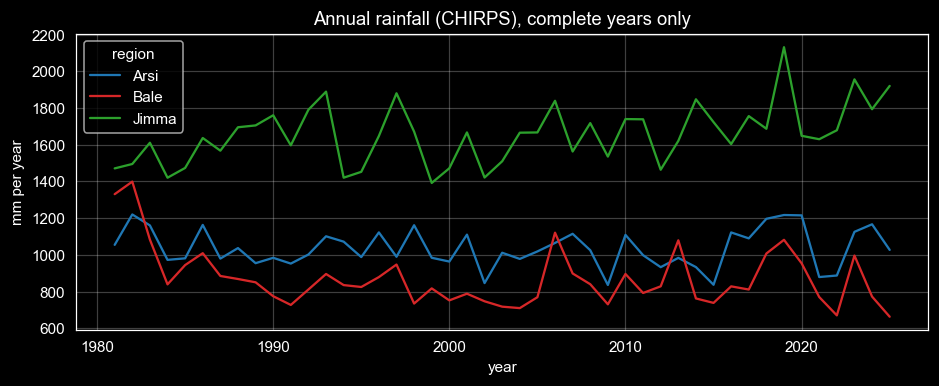

In [24]:
days = rain.assign(year=rain["date"].dt.year).groupby(["region", "year"])["rain_mm"].agg(["sum", "count"])
annual = days[days["count"] >= 365]["sum"].unstack(0)

ax = annual.plot(figsize=(10, 3.5), color=[COLORS[c] for c in annual.columns])
ax.set_title("Annual rainfall (CHIRPS), complete years only")
ax.set_ylabel("mm per year")
plt.show()

## 4. Weather (NASA POWER) and evaporative demand
POWER provides temperature, humidity, wind and solar radiation. From them we calculate two numbers that describe **how fast water leaves the soil**:

* **VPD** (vapor pressure deficit) = saturation vapor pressure - actual vapor pressure. High VPD = thirsty air.
* **ET0** (reference evapotranspiration, FAO-56 Penman-Monteith) = how many mm of water the atmosphere can take per day.

Two details handled in the code: radiation units differ between POWER communities (MJ or kWh per m2), so the code detects the unit,
and wind is converted from 10 m to 2 m height for ET0.

In [25]:
raw_power = read_region_files("NASA_POWER", "nasa_power")
display(raw_power.head())
display(raw_power.describe().loc[["count", "min", "mean", "max"]].round(2))

,date,region,T2M,T2M_MAX,T2M_MIN,RH2M,WS10M,ALLSKY_SFC_SW_DWN
0,1981-01-01,Arsi,13.17,23.60,4.45,42.10,2.57,NaN
1,1981-01-02,Arsi,13.22,23.02,4.75,45.91,3.26,NaN
2,1981-01-03,Arsi,13.88,23.30,6.08,50.06,2.79,NaN
3,1981-01-04,Arsi,13.73,22.83,7.01,51.04,3.16,NaN
4,1981-01-05,Arsi,13.22,22.49,5.61,49.26,3.81,NaN


,date,T2M,T2M_MAX,T2M_MIN,RH2M,WS10M,ALLSKY_SFC_SW_DWN
count,50250,50250.00,50250.00,50250.00,50250.00,50250.00,46752.00
min,1981-01-01 00:00:00,7.91,11.95,0.24,10.16,0.51,3.87
mean,2003-12-06 12:00:00,17.04,23.22,11.89,71.46,2.54,20.52
max,2026-11-10 00:00:00,25.14,33.32,18.90,96.57,8.85,30.25


In [26]:
weather = cd.clean_weather(static)
weather.head()


[weather] NASA POWER + VPD + ET0
  radiation median 20.9 -> treated as MJ/m2/day
      t2m_c  tmax_c  tmin_c  rh_pct  wind10_ms  rad_mj  vpd_kpa  et0_mm
min    7.91   11.95    0.24   10.16       0.51    3.87     0.07    1.11
mean  17.04   23.22   11.89   71.46       2.54   20.52     0.64    3.88
max   25.14   33.32   18.90   96.57       8.85   30.25     2.71    8.32
[saved] weather_daily.csv                rows=  50250  cols=10


,date,region,t2m_c,tmax_c,tmin_c,rh_pct,wind10_ms,rad_mj,vpd_kpa,et0_mm
0,1981-01-01,Arsi,13.17,23.60,4.45,42.10,2.57,NaN,1.086321,NaN
1,1981-01-02,Arsi,13.22,23.02,4.75,45.91,3.26,NaN,0.992563,NaN
2,1981-01-03,Arsi,13.88,23.30,6.08,50.06,2.79,NaN,0.949140,NaN
3,1981-01-04,Arsi,13.73,22.83,7.01,51.04,3.16,NaN,0.926134,NaN
4,1981-01-05,Arsi,13.22,22.49,5.61,49.26,3.81,NaN,0.921969,NaN


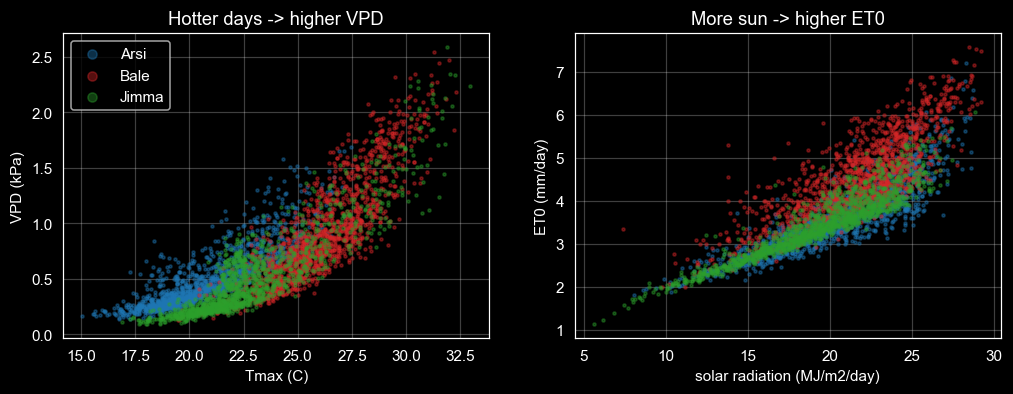

In [27]:
sample = weather.dropna(subset=["tmax_c", "et0_mm"]).sample(4000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for region, g in sample.groupby("region"):
    axes[0].scatter(g["tmax_c"], g["vpd_kpa"], s=4, alpha=0.4, color=COLORS[region], label=region)
    axes[1].scatter(g["rad_mj"], g["et0_mm"], s=4, alpha=0.4, color=COLORS[region], label=region)
axes[0].set(xlabel="Tmax (C)", ylabel="VPD (kPa)", title="Hotter days -> higher VPD")
axes[1].set(xlabel="solar radiation (MJ/m2/day)", ylabel="ET0 (mm/day)", title="More sun -> higher ET0")
axes[0].legend(markerscale=3)
plt.show()

**Check yourself:** VPD usually 0.2-2 kPa and ET0 2-6 mm/day in the highlands. Values far outside that mean a unit problem upstream.

## 5. Soil moisture (ERA5-Land and SMAP)
* **ERA5-Land** soil water layers cover the **whole history (1981 onward)**, so they are the model input. Layer 1 is 0-7 cm, layer 2 is 7-28 cm,
  layer 3 is 28-100 cm.
* **SMAP L3** is a satellite observation of the top ~5 cm (2015 onward, with gaps on days the satellite does not see the area).
* **SMAP L4** is a model-based surface and root-zone product (2015 onward, no gaps).

SMAP is kept in separate columns and used to **validate** ERA5-Land, not mixed into it.

In [28]:
soil = cd.clean_soil_moisture()
soil.dropna(subset=["smap_l4_surface"]).head()


[soil moisture] ERA5-Land (+ SMAP L3, L4)
           sm_l1      sm_l2      sm_l3      sm_l4  smap_l3_am  smap_l3_pm  smap_l3_sm  smap_l4_surface  smap_l4_rootzone
count  50238.000  50238.000  50238.000  50238.000    5369.000    4551.000    8640.000        12726.000         12726.000
min        0.195      0.240      0.257      0.303       0.048       0.025       0.041            0.067             0.170
mean       0.387      0.397      0.404      0.439       0.286       0.257       0.273            0.268             0.303
max        0.504      0.500      0.512      0.516       0.607       0.570       0.607            0.465             0.478
[saved] soil_moisture_daily.csv          rows=  50256  cols=11


,date,region,sm_l1,sm_l2,sm_l3,sm_l4,smap_l3_am,smap_l3_pm,smap_l3_sm,smap_l4_surface,smap_l4_rootzone
12507,2015-03-31,Arsi,0.444722,0.417514,0.335979,0.438575,NaN,NaN,NaN,0.222374,0.255140
12508,2015-04-01,Arsi,0.430938,0.413522,0.336782,0.438354,0.204318,NaN,0.204318,0.208474,0.254241
12509,2015-04-02,Arsi,0.413573,0.407010,0.337227,0.438110,NaN,NaN,NaN,0.196311,0.253028
12510,2015-04-03,Arsi,0.413949,0.401361,0.337479,0.437873,0.124703,0.159805,0.142254,0.177656,0.251039
12511,2015-04-04,Arsi,0.442660,0.417778,0.341789,0.437677,0.177194,NaN,0.177194,0.191626,0.251311


In [29]:
# How often is SMAP L3 empty, per year? (a steady rate = normal satellite gaps; a year at 1.0 = a download problem)
smap_era = soil[soil["date"] >= "2015-03-31"]
empty_by_year = (smap_era.assign(year=smap_era["date"].dt.year)
                 .groupby("year")[["smap_l3_am", "smap_l3_pm", "smap_l4_surface"]]
                 .agg(lambda s: s.isna().mean()).round(2))
empty_by_year

,smap_l3_am,smap_l3_pm,smap_l4_surface
year,,,
2015,0.57,0.64,0.00
2016,0.55,0.63,0.00
2017,0.56,0.63,0.00
2018,0.56,0.63,0.00
2019,0.60,0.66,0.00
2020,0.56,0.64,0.00
2021,0.56,0.64,0.00
2022,0.63,0.69,0.00
2023,0.57,0.66,0.00


## 6. Validation-only tables
These are cleaned now but are **not** model inputs. They are used later to check the model's answers.

* `era5_weather_daily` - ERA5-Land weather in friendly units (Kelvin -> C, metres -> mm, wind U/V -> speed)
* `imerg_daily` - a second rainfall source
* `vegetation` - MODIS and Sentinel-2 NDVI/EVI/NDRE/NDMI. Sentinel-2 has several tiles per date, so they are averaged by date.

In [30]:
cd.clean_era5_weather()
cd.clean_imerg()
cd.clean_vegetation()


[validation] ERA5-Land weather
[saved] era5_weather_daily.csv           rows=  50238  cols=7

[validation] GPM IMERG
[saved] imerg_daily.csv                  rows=  31632  cols=3

[validation] MODIS + Sentinel-2
[saved] vegetation.csv                   rows=   4023  cols=7
             count   min  mean   max
source                              
MODIS       1842.0  0.26  0.58  0.84
Sentinel-2  2171.0 -0.11  0.46  0.82


## 7. Final check

In [31]:
summary = []
for f in sorted(PROC_DIR.glob("*.csv")):
    d = pd.read_csv(f)
    summary.append({"table": f.stem, "rows": len(d), "columns": d.shape[1],
                    "empty_cells_%": round(d.isna().mean().mean() * 100, 1)})
pd.DataFrame(summary)

,table,rows,columns,empty_cells_%
0,data_quality_report,30,17,40.6
1,era5_weather_daily,50238,7,0.0
2,imerg_daily,31632,3,0.0
3,integrated_daily,50127,32,13.3
4,integrated_seasonal,414,15,0.4
5,integrated_yearly,138,14,0.5
6,label_sensitivity,16,5,0.0
7,no_onset_found,0,3,NaN
8,onset_events,230,11,4.7
9,rainfall_daily,50127,4,0.0
